# Planetary Boundary Transgressions and Divergent Socio-Economic Pathways
## A Cross-National Quantitative Analysis — Full Reproducible Analysis
**Author:** Sahil (M2022BSASS023) | **Institution:** Tata Institute of Social Sciences, Mumbai  
**Supervisor:** Dr. Kamal Murari | **Year:** 2026  
**GitHub:** https://github.com/sahiljangra12

---
### Notebook Structure
1. Data Loading & Cleaning (195-country sample)
2. Planetary Pressure Index (PPI) Construction
3. Descriptive Statistics
4. K-Means Clustering (Elbow + K=4)
5. Cluster Profiles & Transition Matrices
6. Regression Analysis
7. All Figures (Figures 2–10)



## 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# ── Plotting style ──────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 150, 'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'savefig.bbox': 'tight',
    'savefig.facecolor': 'white',
})

# ── Cluster colour scheme ───────────────────────────────────
C_COLORS = {
    'C1_HighPress_LowDev':  '#E24B4A',
    'C2_HighPress_HighDev': '#C77B17',
    'C3_LowPress_LowDev':   '#3B9E5A',
    'C4_Transitioning':     '#2B7DB8',
}
C_LABELS = {
    'C1_HighPress_LowDev':  'C1: High Pressure / Low Dev',
    'C2_HighPress_HighDev': 'C2: High Pressure / High Dev',
    'C3_LowPress_LowDev':   'C3: Low Pressure / Low Dev',
    'C4_Transitioning':     'C4: Transitioning / Decoupler',
}
DECADE_COLORS = {'D1':'#1a5276','D2':'#2e8b57','D3':'#c0392b'}
DECADE_LABELS = {'D1':'1990–2000','D2':'2000–2010','D3':'2010–2023'}
print("✓ Setup complete")

✓ Setup complete


## 2. Data Loading, Region Removal & 195-Country Filter

In [2]:
# ── Load updated dataset ───────────────────────────────────
df = pd.read_excel('../data/thesis_dataset.xlsx', sheet_name='Data')
df.rename(columns={k: k.replace('★ ','') for k in df.columns if '★' in k}, inplace=True)
print(f"Raw dataset: {df.shape[0]} rows, {df['country'].nunique()} entries, {df['year'].min()}–{df['year'].max()}")

# ── Remove World Bank regional aggregates ──────────────────
region_keywords = [
    'region','world','ibrd','ida','oecd','africa eastern','africa western',
    'arab world','east asia','europe &','latin america','middle east',
    'central europe','fragile','heavily indebted','least developed','low &',
    'small states','not classified','european union','middle income',
    'high income','low income','upper middle','lower middle','north america',
    'south asia','sub-saharan','pacific island','caribbean small','other small','euro area'
]
all_entries = df['country'].unique()
regions = [c for c in all_entries if any(kw in c.lower() for kw in region_keywords)]
true_countries = [c for c in all_entries if c not in regions]
print(f"Regional aggregates removed: {len(regions)}")
print(f"Sovereign countries remaining: {len(true_countries)}")

# ── Decade assignment ──────────────────────────────────────
df['decade'] = pd.cut(df['year'], bins=[1989,2000,2010,2023], labels=['D1','D2','D3'])
df_c = df[df['country'].isin(true_countries) & (df['year']!=2024) & df['decade'].notna()].copy()

# ── Population filter ≥100,000 → exactly 195 countries ─────
pop_avg = df_c.groupby('country')['population'].mean()
countries_195 = pop_avg[pop_avg >= 100000].index.tolist()
df195 = df_c[df_c['country'].isin(countries_195)].copy()
print(f"\n✓ Final analytical sample: {len(countries_195)} countries")
print(f"  Rows: {len(df195)} | Per decade: {df195.groupby('decade').size().to_dict()}")

Raw dataset: 9100 rows, 260 entries, 1990–2024
Regional aggregates removed: 40
Sovereign countries remaining: 220

✓ Final analytical sample: 195 countries
  Rows: 6630 | Per decade: {'D1': 2145, 'D2': 1950, 'D3': 2535}


## 3. Planetary Pressure Index (PPI) Construction

In [3]:
# ── Variable definitions ─────────────────────────────────
PPI_VARS    = ['renewable_energy','forest_pct','agri_land','fertilizer','pm25','energy_use_pc']
INVERSE     = ['renewable_energy','forest_pct']   # higher = less pressure → reverse sign
SE_VARS     = ['gdp_pc','life_expectancy','infant_mortality',
               'urban_population_pct','unemployment','female_labor']
EXTRA_VARS  = ['population','co2_pc','gdp_pc_ppp','clean_water_access',
               'sanitation_access','gov_effectiveness']
# Optional context variables: kept only if present in the dataset (not used in PPI, clustering or regression)
EXTRA_VARS  = [v for v in EXTRA_VARS if v in df195.columns]

# ── Decade aggregation (country mean) ─────────────────────
decade_df = df195.groupby(['country','iso3','decade'])[PPI_VARS + SE_VARS + EXTRA_VARS].mean().reset_index()

# ── Step 1: Directionality coding ─────────────────────────
dd = decade_df.copy()
for v in INVERSE:
    dd[v+'_coded'] = -dd[v]
for v in [v for v in PPI_VARS if v not in INVERSE]:
    dd[v+'_coded'] = dd[v]
coded_cols = [v+'_coded' for v in PPI_VARS]

# ── Step 2: Global z-score standardisation ────────────────
for v in coded_cols:
    m, s = dd[v].mean(), dd[v].std()
    dd[v+'_z'] = (dd[v] - m) / s
z_cols = [v+'_z' for v in coded_cols]

# ── Step 3: PPI = mean z-score (min 4 of 6 vars) ─────────
dd['ppi_count'] = dd[z_cols].notna().sum(axis=1)
dd['ppi_raw']   = dd[z_cols].mean(axis=1)
dd.loc[dd['ppi_count'] < 4, 'ppi_raw'] = np.nan

# ── Step 4: Rescale 0–100 per decade ─────────────────────
for d in ['D1','D2','D3']:
    mask = dd['decade'] == d
    mn, mx = dd.loc[mask,'ppi_raw'].min(), dd.loc[mask,'ppi_raw'].max()
    dd.loc[mask,'ppi_scaled'] = (dd.loc[mask,'ppi_raw'] - mn) / (mx - mn) * 100

print("✓ PPI constructed")
print("\nPPI summary by decade:")
print(dd.groupby('decade')['ppi_scaled'].agg(['mean','std','min','max','count']).round(2))

✓ PPI constructed

PPI summary by decade:
         mean    std  min    max  count
decade                                 
D1      34.94  14.26  0.0  100.0    185
D2      37.64  16.43  0.0  100.0    189
D3      39.85  16.38  0.0  100.0    191


## 4. Descriptive Statistics (Table 4)

In [4]:
report_vars = {
    'ppi_scaled': 'PPI Score (0–100)',
    'renewable_energy': 'Renewable Energy (%)',
    'forest_pct': 'Forest Cover (%)',
    'agri_land': 'Agricultural Land (%)',
    'fertilizer': 'Fertiliser Use (kg/ha)',
    'pm25': 'PM2.5 Exposure (µg/m³)',
    'energy_use_pc': 'Energy Use per Capita (kgoe)',
    'gdp_pc': 'GDP per Capita (USD)',
    'life_expectancy': 'Life Expectancy (years)',
    'infant_mortality': 'Infant Mortality (per 1,000)',
    'urban_population_pct': 'Urbanisation (%)',
    'female_labor': 'Female Labour Participation (%)',
    'unemployment': 'Unemployment Rate (%)',
}

rows = []
for var, label in report_vars.items():
    for d in ['D1','D2','D3']:
        col = dd[dd['decade']==d][var].dropna()
        rows.append({
            'Variable': label, 'Decade': DECADE_LABELS[d],
            'Mean': round(col.mean(),2), 'SD': round(col.std(),2),
            'Min': round(col.min(),2), 'Max': round(col.max(),2),
            'N': int(col.notna().sum())
        })

desc_table = pd.DataFrame(rows)
print("Table 4. Descriptive Statistics by Decade")
print(desc_table.to_string(index=False))

Table 4. Descriptive Statistics by Decade
                       Variable    Decade     Mean       SD    Min       Max   N
              PPI Score (0–100) 1990–2000    34.94    14.26   0.00    100.00 185
              PPI Score (0–100) 2000–2010    37.64    16.43   0.00    100.00 189
              PPI Score (0–100) 2010–2023    39.85    16.38   0.00    100.00 191
           Renewable Energy (%) 1990–2000    35.52    32.50   0.00     96.26 190
           Renewable Energy (%) 2000–2010    33.37    30.71   0.00     97.52 192
           Renewable Energy (%) 2010–2023    31.88    28.16   0.00     95.75 193
               Forest Cover (%) 1990–2000    33.16    24.65   0.00     95.69 187
               Forest Cover (%) 2000–2010    32.86    24.08   0.00     95.44 189
               Forest Cover (%) 2010–2023    31.99    23.67   0.00     94.88 192
          Agricultural Land (%) 1990–2000    38.83    21.75   0.55     85.35 188
          Agricultural Land (%) 2000–2010    38.50    21.64   0.48 

## 5. K-Means Clustering

In [5]:
# ── Elbow + silhouette across K=2 to 8 ──────────────────
CLUSTER_VARS = ['ppi_scaled','gdp_pc','life_expectancy','infant_mortality','urban_population_pct']
elbow_results = {}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for i, d in enumerate(['D1','D2','D3']):
    sub = dd[dd['decade']==d].dropna(subset=CLUSTER_VARS)
    scaler = StandardScaler()
    scaled = scaler.fit_transform(sub[CLUSTER_VARS])
    inertias, sils = [], []
    for k in range(2,9):
        km = KMeans(n_clusters=k, random_state=42, n_init=20)
        labs = km.fit_predict(scaled)
        inertias.append(km.inertia_)
        sils.append(silhouette_score(scaled, labs))
    elbow_results[d] = {'inertia': inertias, 'silhouette': sils}
    
    ax = axes[i]
    ax2 = ax.twinx()
    k_vals = list(range(2,9))
    l1, = ax.plot(k_vals, inertias, 'o-', color='#1a5276', lw=2, ms=6, label='Inertia')
    l2, = ax2.plot(k_vals, sils, 's--', color='#c0392b', lw=2, ms=6, label='Silhouette')
    ax.axvline(4, color='#2e8b57', lw=2, ls=':', label='K=4')
    ax.set_xlabel('K'); ax.set_ylabel('WCSS', color='#1a5276')
    ax2.set_ylabel('Silhouette', color='#c0392b')
    ax.set_title(f'{DECADE_LABELS[d]}\nSilhouette@K=4: {sils[2]:.3f}', fontweight='bold')
    ax.legend(fontsize=7.5)
plt.suptitle('Figure 3. Elbow Method and Silhouette Scores', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/fig3_elbow_silhouette.png', dpi=150)
plt.show()
print("✓ K=4 confirmed as optimal across all three decades")

✓ K=4 confirmed as optimal across all three decades


In [6]:
# ── Final K=4 clustering per decade ─────────────────────
cluster_results = {}
dd_clustered = dd.copy()

for d in ['D1','D2','D3']:
    sub = dd_clustered[dd_clustered['decade']==d].copy()
    sub_cl = sub.dropna(subset=CLUSTER_VARS)
    scaler = StandardScaler()
    scaled = scaler.fit_transform(sub_cl[CLUSTER_VARS])
    km = KMeans(n_clusters=4, random_state=42, n_init=30, max_iter=500)
    sub_cl = sub_cl.copy()
    sub_cl['cluster_raw'] = km.fit_predict(scaled)
    sil = silhouette_score(scaled, sub_cl['cluster_raw'])
    
    cmeans = sub_cl.groupby('cluster_raw')[['ppi_scaled','gdp_pc']].mean()
    ppi_med = sub_cl['ppi_scaled'].median()
    gdp_med = sub_cl['gdp_pc'].median()
    label_map = {}
    for cid, row in cmeans.iterrows():
        hi_ppi = row['ppi_scaled'] > ppi_med
        hi_gdp = row['gdp_pc'] > gdp_med
        if hi_ppi and not hi_gdp:   label_map[cid] = 'C1_HighPress_LowDev'
        elif hi_ppi and hi_gdp:     label_map[cid] = 'C2_HighPress_HighDev'
        elif not hi_ppi and not hi_gdp: label_map[cid] = 'C3_LowPress_LowDev'
        else:                       label_map[cid] = 'C4_Transitioning'
    
    # Fix if any labels duplicate
    used = list(label_map.values())
    all_lbls = ['C1_HighPress_LowDev','C2_HighPress_HighDev','C3_LowPress_LowDev','C4_Transitioning']
    missing = [l for l in all_lbls if l not in used]
    dupes   = [l for l in all_lbls if used.count(l) > 1]
    if missing and dupes:
        for dup in dupes:
            dup_ids = sorted([k for k,v in label_map.items() if v==dup],
                              key=lambda x: cmeans.loc[x,'ppi_scaled'])
            label_map[dup_ids[0]] = missing.pop(0)
    
    sub_cl['cluster'] = sub_cl['cluster_raw'].map(label_map)
    cluster_results[d] = {'data': sub_cl, 'silhouette': sil}
    dd_clustered.loc[sub_cl.index, 'cluster'] = sub_cl['cluster']
    
    print(f"\nDecade {d}: silhouette={sil:.3f}, n={len(sub_cl)}")
    print(sub_cl.groupby('cluster')[['ppi_scaled','gdp_pc','life_expectancy',
                                      'infant_mortality','urban_population_pct']].mean().round(1))
    print("Sizes:", sub_cl['cluster'].value_counts().to_dict())


Decade D1: silhouette=0.311, n=179
                      ppi_scaled   gdp_pc  life_expectancy  infant_mortality  \
cluster                                                                        
C1_HighPress_LowDev         40.3   2974.7             69.0              30.0   
C2_HighPress_HighDev        47.4  22802.0             76.4               7.9   
C3_LowPress_LowDev          27.6    439.3             52.1              96.0   
C4_Transitioning            23.8   1681.7             66.2              35.9   

                      urban_population_pct  
cluster                                     
C1_HighPress_LowDev                   61.7  
C2_HighPress_HighDev                  79.3  
C3_LowPress_LowDev                    28.0  
C4_Transitioning                      37.1  
Sizes: {'C1_HighPress_LowDev': 62, 'C3_LowPress_LowDev': 50, 'C2_HighPress_HighDev': 34, 'C4_Transitioning': 33}

Decade D2: silhouette=0.307, n=182
                      ppi_scaled   gdp_pc  life_expectancy  infa

## 6. Cluster Transitions

In [7]:
# ── Transition matrices D1→D2 and D2→D3 ────────────────
order = ['C1_HighPress_LowDev','C2_HighPress_HighDev','C3_LowPress_LowDev','C4_Transitioning']

for d1, d2 in [('D1','D2'), ('D2','D3')]:
    d1_data = cluster_results[d1]['data'][['country','cluster']].rename(columns={'cluster':f'D{d1[-1]}'})
    d2_data = cluster_results[d2]['data'][['country','cluster']].rename(columns={'cluster':f'D{d2[-1]}'})
    merged = d1_data.merge(d2_data, on='country')
    tm = pd.crosstab(merged[f'D{d1[-1]}'], merged[f'D{d2[-1]}'])
    for c in order:
        if c not in tm.index: tm.loc[c] = 0
        if c not in tm.columns: tm[c] = 0
    tm = tm.reindex(index=order, columns=order, fill_value=0)
    short = {c: c[:2] for c in order}
    tm.index = [short[c] for c in tm.index]
    tm.columns = [short[c] for c in tm.columns]
    print(f"\nTransition Matrix {d1}→{d2}:")
    print(tm.to_string())
    persist = sum([tm.loc[f'C{i}',f'C{i}'] for i in range(1,5)])
    print(f"Countries remaining in same cluster: {persist}/{len(merged)} ({persist/len(merged)*100:.0f}%)")


Transition Matrix D1→D2:
    C1  C2  C3  C4
C1  57   1   3   1
C2   0  34   0   0
C3   0   0  46   4
C4   5   0   3  25
Countries remaining in same cluster: 162/179 (91%)

Transition Matrix D2→D3:
    C1  C2  C3  C4
C1   1   0   0  63
C2   0  31   0   4
C3  36   0  17   0
C4   2   0  10  18
Countries remaining in same cluster: 67/182 (37%)


## 7. Regression Analysis

In [8]:
# ── OLS regression: PPI vs each socio-economic outcome ──
from scipy import stats as scs

se_outcomes = {
    'gdp_pc': 'GDP per Capita (log)',
    'life_expectancy': 'Life Expectancy',
    'infant_mortality': 'Infant Mortality',
    'urban_population_pct': 'Urbanisation',
    'unemployment': 'Unemployment',
    'female_labor': 'Female Labour Participation',
}

all_reg_results = []
for d in ['D1','D2','D3']:
    sub = cluster_results[d]['data']
    for var, label in se_outcomes.items():
        valid = sub[['ppi_scaled', var]].dropna()
        if len(valid) < 20: continue
        slope, intercept, r, p, se = scs.linregress(valid['ppi_scaled'], valid[var])
        sig = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns'))
        all_reg_results.append({
            'Decade': DECADE_LABELS[d], 'Outcome': label,
            'r': round(r,3), 'β': round(slope,4),
            'p-value': round(p,4), 'Sig.': sig, 'n': len(valid)
        })

reg_table = pd.DataFrame(all_reg_results)
print("Table 10. Regression Results: PPI and Socio-Economic Outcomes")
print(reg_table.to_string(index=False))

Table 10. Regression Results: PPI and Socio-Economic Outcomes
   Decade                     Outcome      r        β  p-value Sig.   n
1990–2000        GDP per Capita (log)  0.347 221.0165   0.0000  *** 179
1990–2000             Life Expectancy  0.402   0.2718   0.0000  *** 179
1990–2000            Infant Mortality -0.359  -0.9265   0.0000  *** 179
1990–2000                Urbanisation  0.458   0.7290   0.0000  *** 179
1990–2000                Unemployment  0.033   0.0135   0.6593   ns 176
1990–2000 Female Labour Participation -0.346  -0.4089   0.0000  *** 176
2000–2010        GDP per Capita (log)  0.339 307.8944   0.0000  *** 182
2000–2010             Life Expectancy  0.365   0.2034   0.0000  *** 182
2000–2010            Infant Mortality -0.316  -0.5287   0.0000  *** 182
2000–2010                Urbanisation  0.420   0.5692   0.0000  *** 182
2000–2010                Unemployment  0.002   0.0007   0.9793   ns 179
2000–2010 Female Labour Participation -0.368  -0.3574   0.0000  *** 179
20

## 8. All Figures

Figure: fig3_elbow_silhouette.png


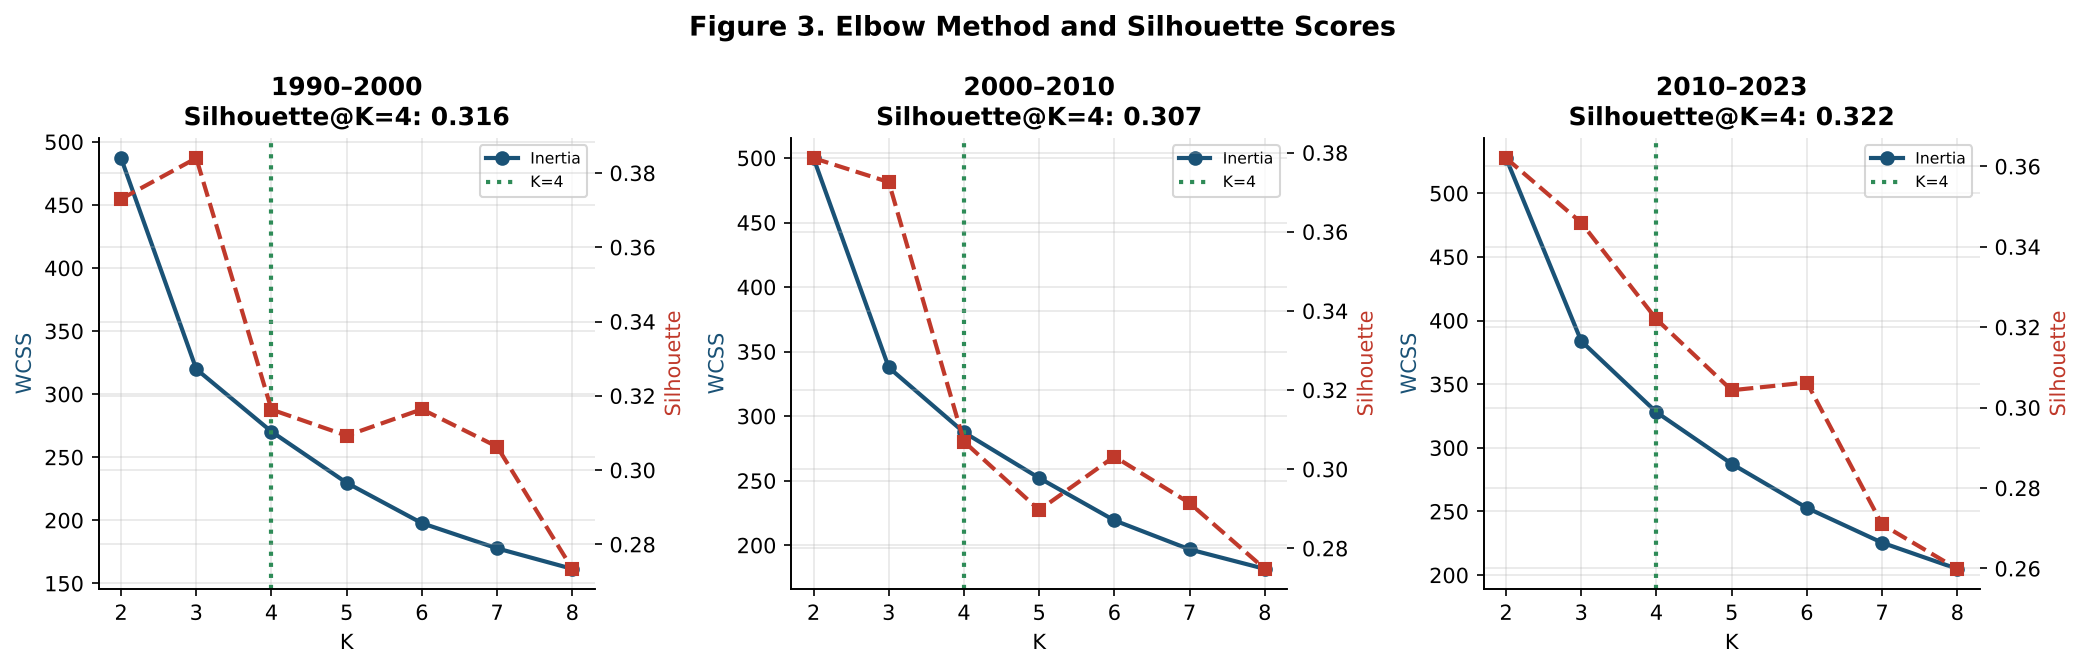

In [9]:
# Figures saved by the cells above are written to ../figures/
from IPython.display import Image, display
import os

FIG_DIR = '../figures'
figs = sorted(f for f in os.listdir(FIG_DIR) if f.startswith('fig') and f.endswith('.png'))
for f in figs:
    print(f"Figure: {f}")
    display(Image(filename=os.path.join(FIG_DIR, f)))

## 9. Reproducibility

### Reproducibility Note
All data, code, and outputs for this analysis are available at:  
**https://github.com/sahiljangra12/Thesis**

Dataset sources: World Bank WDI, FAOSTAT, WHO Global Health Observatory, ILO ILOSTAT, UNDP HDR.  
All datasets are open-access. No API keys required.
